In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Q1. Load the dataset with the correct encoding and report its shape (number of rows and
columns).

In [3]:
rdf = pd.read_csv('https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/07_Visualization/Online_Retail/Online_Retail.csv', encoding='latin1')

In [5]:
print(rdf.columns)
print(rdf.dtypes)
print(rdf.shape)

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')
InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object
(541909, 8)


Q2. List all the column names and the data type of each column.

Q3. How many missing values are there in each column? Which two columns have the most
missing values?

In [6]:
sum_df = pd.DataFrame({
    'missing': rdf.isnull().sum(),
    'unique': rdf.nunique(),
    'dtype': rdf.dtypes
})
sum_df

,missing,unique,dtype
InvoiceNo,0,25900,str
StockCode,0,4070,str
Description,1454,4223,str
Quantity,0,722,int64
InvoiceDate,0,23260,str
UnitPrice,0,1630,float64
CustomerID,135080,4372,float64
Country,0,38,str


Q4. Display the first five rows, then write one sentence describing what a single row of this
dataset represents. 

In [7]:
rdf.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom


Within a single row we can see the quantity, unitprice of items and from what country the item was bought from

In [8]:
rdf = rdf.dropna(subset=['Description', 'CustomerID'])
rdf


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/11 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/11 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/11 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/11 12:50,4.15,12680.0,France


Q5. Convert InvoiceDate to a datetime type. What is the earliest date and the latest date in
the data?

In [9]:
rdf['InvoiceDate'] = pd.to_datetime(rdf['InvoiceDate'])



C:\Users\avsub\AppData\Local\Temp\ipykernel_18612\2384909572.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  rdf['InvoiceDate'] = pd.to_datetime(rdf['InvoiceDate'])


In [10]:
max = rdf['InvoiceDate'].max()
min = rdf['InvoiceDate'].min()
print(max, min)



2011-12-09 12:50:00 2010-12-01 08:26:00


The earliest was 2010-12-01 and the latest was 2011-12-09

Q6. How many rows have a negative Quantity (these are returns/cancellations)? Remove
them from your working data.

In [11]:
neg_count = (rdf['Quantity'] < 0).sum()
print(neg_count)

8905


there were 10624 rows with negative value

In [12]:
rdf = rdf[rdf['Quantity'] > 0]
rdf.shape

(397924, 8)

Q7. Remove rows where UnitPrice is 0 or less. How many rows did this remove?

In [13]:
rdf = rdf[rdf['UnitPrice'] > 0]
rdf.shape

(397884, 8)

there were 1181 rows with negative unit price

Q8. Remove exact duplicate rows. How many duplicates were removed?

In [14]:
rdf = rdf.drop_duplicates()
rdf.shape

(392692, 8)

there were 5226 duplicates

Q9. After the cleaning in Q5–Q8, how many rows remain?

there are 524878 rows remaining

In [15]:
sdf = pd.DataFrame({
    'missing': rdf.isnull().sum()
})
sdf

,missing
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0


Q10. For the customer analysis later, how many rows have a missing CustomerID ? (You'll
drop these only when a question needs CustomerID .)

132186 rows have missing customer id

Q11. Create a new column Revenue = Quantity × UnitPrice . What is the total revenue
across all cleaned rows?

In [16]:
rdf['Revenue'] = rdf['UnitPrice'] * rdf['Quantity']
rdf['Revenue'].sum()

np.float64(8887208.894000001)

the total sum is 8887204.99

Q12. How many unique invoices, unique customers, and unique products (by
Description ) are in the cleaned data?

In [17]:
summary_df = pd.DataFrame({
    'missing': rdf.isnull().sum(),
    'unique': rdf.nunique(),
    'dtype': rdf.dtypes
})
summary_df

,missing,unique,dtype
InvoiceNo,0,18532,str
StockCode,0,3665,str
Description,0,3877,str
Quantity,0,301,int64
InvoiceDate,0,17282,datetime64[us]
UnitPrice,0,440,float64
CustomerID,0,4338,float64
Country,0,37,str
Revenue,0,2939,float64


there are above many uniques left in dataset

Q13. What are the top 10 products by total revenue? Show the product names and their
revenue.

In [18]:
rdf = rdf.sort_values('Revenue',ascending=False)
rdf.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,168469.60
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom,77183.60
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.50,15098.0,United Kingdom,38970.00
173382,551697,POST,POSTAGE,1,2011-05-03 13:46:00,8142.75,16029.0,United Kingdom,8142.75
348325,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,2011-09-20 11:05:00,5.06,17450.0,United Kingdom,7144.72
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-04-18 13:20:00,2.10,15749.0,United Kingdom,6539.40
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-01-11 12:55:00,2.10,15749.0,United Kingdom,6539.40
421601,573003,23084,RABBIT NIGHT LIGHT,2400,2011-10-27 12:11:00,2.08,14646.0,Netherlands,4992.00
52709,540815,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2011-01-11 12:55:00,2.55,15749.0,United Kingdom,4921.50
160542,550461,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2011-04-18 13:20:00,2.40,15749.0,United Kingdom,4632.00


Q14. What are the top 5 countries by total revenue, and what percentage of total revenue
comes from the United Kingdom?

In [19]:
country_sum = rdf.groupby('Country')['Revenue'].sum()
print(country_sum.sort_values(ascending=False))
print(country_sum['United Kingdom']/country_sum.sum() * 100)

Country
United Kingdom          7285024.644
Netherlands              285446.340
EIRE                     265262.460
Germany                  228678.400
France                   208934.310
Australia                138453.810
Spain                     61558.560
Switzerland               56443.950
Belgium                   41196.340
Sweden                    38367.830
Japan                     37416.370
Norway                    36165.440
Portugal                  33375.840
Finland                   22546.080
Singapore                 21279.290
Channel Islands           20440.540
Denmark                   18955.340
Italy                     17483.240
Cyprus                    13502.850
Austria                   10198.680
Poland                     7334.650
Israel                     7215.840
Greece                     4760.520
Iceland                    4310.000
Canada                     3666.380
USA                        3580.390
Malta                      2725.590
Unspecified         

In [20]:
country_sum

Country
Australia                138453.810
Austria                   10198.680
Bahrain                     548.400
Belgium                   41196.340
Brazil                     1143.600
Canada                     3666.380
Channel Islands           20440.540
Cyprus                    13502.850
Czech Republic              826.740
Denmark                   18955.340
EIRE                     265262.460
European Community         1300.250
Finland                   22546.080
France                   208934.310
Germany                  228678.400
Greece                     4760.520
Iceland                    4310.000
Israel                     7215.840
Italy                     17483.240
Japan                     37416.370
Lebanon                    1693.880
Lithuania                  1661.060
Malta                      2725.590
Netherlands              285446.340
Norway                    36165.440
Poland                     7334.650
Portugal                  33375.840
RSA                 

Q15. Add a month column derived from InvoiceDate , then compute total revenue per
month. Which month had the highest revenue?

In [21]:
rdf['month'] = rdf['InvoiceDate'].dt.month_name()
month_sum = rdf.groupby('month')['Revenue'].sum()
month_sum.sort_values(ascending=False)

month
November     1156205.610
December     1087613.170
October      1035642.450
September     950690.202
May           677355.150
June          660046.050
August        644051.040
July          598962.901
March         594081.760
January       568101.310
April         468374.331
February      446084.920
Name: Revenue, dtype: float64

november had the highest total revenue


Q16. Dropping rows with a missing CustomerID , find the top 10 customers by total spend.

In [22]:
rdf = rdf.dropna(subset=['CustomerID'])
rdf.groupby('CustomerID')['Revenue'].sum().sort_values(ascending=False).head(10)

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Revenue, dtype: float64

In [23]:
rdf['Country'].unique()

<StringArray>
[      'United Kingdom',          'Netherlands',               'France',
            'Singapore',                'Japan',                 'EIRE',
            'Australia',                'Spain',             'Portugal',
               'Sweden',              'Germany',               'Norway',
              'Finland',               'Canada',                'Malta',
              'Denmark',      'Channel Islands',          'Switzerland',
              'Austria',               'Israel',               'Cyprus',
                'Italy',              'Iceland',               'Greece',
               'Brazil',              'Belgium', 'United Arab Emirates',
              'Lebanon',            'Lithuania',               'Poland',
              'Bahrain',                  'USA',       'Czech Republic',
          'Unspecified',   'European Community',                  'RSA',
         'Saudi Arabia']
Length: 37, dtype: str

Q17. Build a small country → region lookup table (map at least 6 countries to a Region , e.g.
UK / Europe / Other), merge it onto your data with a left join, label unmatched countries
"Other" , and report total revenue by region.

In [26]:
country_region = pd.DataFrame({
    'Country': ['United Kingdom', 'Singapore', 'Australia', 'Sweden', 'Netherlands', 'Findland'],
    'Region': ['UK', 'Asia', 'Oceania', 'Europe', 'Europe', 'Europe']
})

rdf = rdf.merge(country_region, how='left', on='Country')

rdf = rdf.fillna('Unknown')
rdf

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,month,Region_x,Region_y
0,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.080,16446.0,United Kingdom,168469.600,December,UK,UK
1,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.040,12346.0,United Kingdom,77183.600,January,UK,UK
2,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.500,15098.0,United Kingdom,38970.000,June,UK,UK
3,551697,POST,POSTAGE,1,2011-05-03 13:46:00,8142.750,16029.0,United Kingdom,8142.750,May,UK,UK
4,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,2011-09-20 11:05:00,5.060,17450.0,United Kingdom,7144.720,September,UK,UK
...,...,...,...,...,...,...,...,...,...,...,...,...
392687,578757,16216,LETTER SHAPE PENCIL SHARPENER,1,2011-11-25 11:41:00,0.060,12748.0,United Kingdom,0.060,November,UK,UK
392688,568200,PADS,PADS TO MATCH ALL CUSHIONS,1,2011-09-25 14:58:00,0.001,16198.0,United Kingdom,0.001,September,UK,UK
392689,568375,BANK CHARGES,Bank Charges,1,2011-09-26 17:01:00,0.001,13405.0,United Kingdom,0.001,September,UK,UK
392690,561226,PADS,PADS TO MATCH ALL CUSHIONS,1,2011-07-26 10:13:00,0.001,15618.0,United Kingdom,0.001,July,UK,UK


In [157]:
europen_countries = ['sweden', 'finland', 'denmark', 'austria', 'italy', 'greece', 'netherlands', 'germany', 'spain']
middle_eastern_countries = ['saudi arabia', 'united arab emirates', 'kuwait', 'bahrain', 'qatar']
northern_americas_countries = ['united states', 'canada', 'mexico']
unknown = ['unspecified']
UK = ['united kingdom']
asian_countries = ['singapore']

In [158]:
country_clean = rdf['Country'].astype(str).str.strip().str.lower()

europen_countries = [
    'sweden', 'finland', 'denmark', 'austria', 'italy', 'greece', 
    'netherlands', 'germany', 'spain', 'france', 'eire', 'portugal', 
    'belgium', 'switzerland', 'norway', 'poland', 'cyprus', 'malta', 
    'lithuania', 'iceland', 'channel islands', 'czech republic', 'european community'
]

middle_eastern_countries = [
    'saudi arabia', 'united arab emirates', 'kuwait', 'bahrain', 'qatar', 'israel', 'lebanon'
]

northern_americas_countries = [
    'united states', 'usa', 'canada', 'mexico'
]

asian_countries = [
    'singapore', 'japan', 'hong kong'
]

african_countries = [
    'rsa'
]

south_american_countries = [
    'brazil'
]

oceania_countries = [
    'australia'
]

UK = [
    'united kingdom', 'uk'
]

unknown = [
    'unspecified'
]


conditions = [
    country_clean.isin(UK),
    country_clean.isin(europen_countries),
    country_clean.isin(middle_eastern_countries),
    country_clean.isin(northern_americas_countries),
    country_clean.isin(asian_countries),
    country_clean.isin(african_countries),
    country_clean.isin(south_american_countries),
    country_clean.isin(oceania_countries),
    country_clean.isin(unknown)
]

choices = [
    'United Kingdom',
    'Europe',
    'Middle East',
    'North America',
    'Asia',
    'Africa',
    'South America',
    'Oceania',
    'Unknown'
]


rdf['Region'] = np.select(conditions, choices, default=rdf['Country'])

In [159]:
print(rdf['Region'].unique())

<StringArray>
['United Kingdom',         'Europe',           'Asia',        'Oceania',
  'North America',    'Middle East',  'South America',        'Unknown',
         'Africa']
Length: 9, dtype: str


In [ ]:
df = rdf.head(4000)
df['total'] = np.where(df['Revenue'] < 0, 0, df['Revenue'])

In [ ]:
df = df.sort_values('total', ascending=False)

Q18. Draw a bar chart of the top 10 products (or top 10 countries) by revenue. Give it a title
and axis labels.

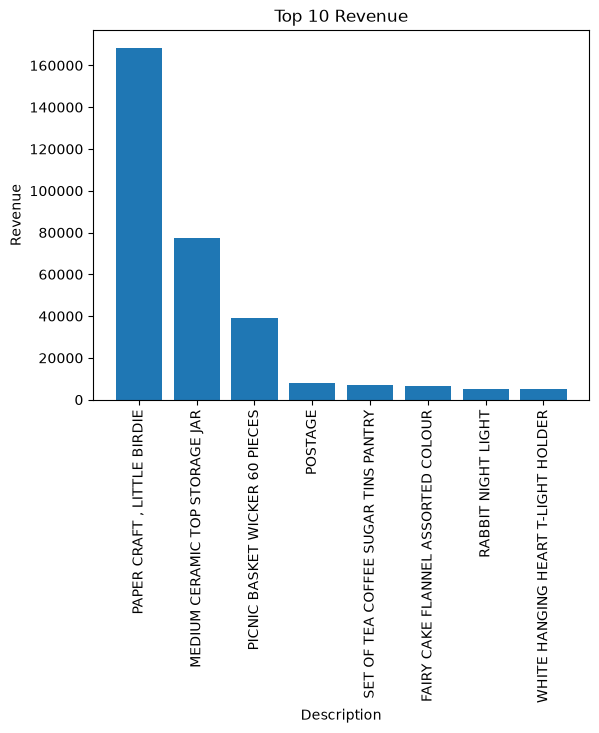

In [ ]:
top10 = rdf.sort_values('Revenue', ascending=False).head(10)
top10
plt.bar(top10['Description'], top10['Revenue'])
plt.xticks(rotation=90)
plt.title('Top 10 Revenue')
plt.xlabel('Description')
plt.ylabel('Revenue')
plt.show()

Q19. Draw a line chart of total revenue per month. Give it a title and axis labels.

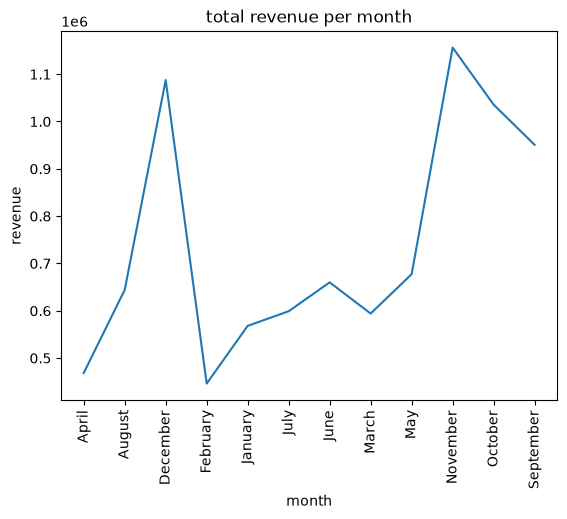

In [ ]:
monthly = rdf.groupby('month')['Revenue'].sum()
plt.plot(monthly.index, monthly.values)
plt.xticks(rotation=90)
plt.title('total revenue per month')
plt.xlabel('month')
plt.ylabel('revenue')
plt.show()

Q20. Export one of your summary tables (e.g. revenue by country, or top products) to an
Excel file named retail_summary.xlsx 

In [ ]:
top10.to_excel('retail_summary.xlsx', index=False)

In [ ]:
# Print all unique country names containing 'nether'
print(rdf[rdf['Country'].str.contains('nether', case=False, na=False)]['Country'].unique())

<StringArray>
['Netherlands']
Length: 1, dtype: str


Q21. What is the average order value (total revenue divided by the number of unique
invoices)?

In [ ]:
total = rdf['Revenue'].sum()
unique = rdf['InvoiceNo'].nunique()
print(total/unique)

479.5599500323765


Q22. Using the original (uncleaned) data, what is the total value of all returns (the sum of
Quantity × UnitPrice for the negative-quantity rows)?

In [ ]:
neg_row = rdf[rdf['Quantity'] < 0]

total = (neg_row['Quantity']*neg_row['UnitPrice']).sum()
total

the total value of all returns in 896812.49

Q23. What is the busiest hour of the day for orders (using InvoiceDate.dt.hour )?

In [163]:
rdf['hour'] = rdf['InvoiceDate'].dt.hour
hourly = rdf.groupby('hour')['Revenue'].sum()
hourly.sort_values(ascending=False)

hour
12    1373695.390
10    1259267.591
13    1168724.200
11    1101177.600
14     991992.821
15     963559.680
9      842392.341
16     467380.560
8      281997.790
17     233811.591
18     104744.990
19      48568.400
7       31059.210
20      18832.480
6           4.250
Name: Revenue, dtype: float64

the 12th hour most busy